# 03 · Tyre degradation model

Plots and tables only. The model, fitting and evaluation code is in
`f1strat.deg_model`; the spec is `docs/model.md`.

Fits are loaded from `models/`: the full posteriors if present (rebuild with
`pitwall fit all`, about 100 min), else the committed thinned copies (1,000
draws), so results here can differ from `docs/model.md` in the third decimal.

In [1]:
from pathlib import Path

import pandas as pd

from f1strat import figure_data as fd
from f1strat import figures as F
from f1strat.clean import clean_laps
from f1strat.data import load_season
from f1strat.deg_model import (
    FULL_FIT_PATH,
    SPLITS,
    comparison_table,
    deg_by_race,
    effects_table,
    error_by_tyre_age,
    interval_widening_factor,
    load_fit_or_thin,
    predict,
    prepare,
    season_deg_table,
    split_fit_path,
    stint_team_confounding,
    team_compound_summary,
)

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Figures are drawn by f1strat.figures, the same functions `pitwall figures` uses to
# write reports/figures from data/figures; here they are only shown.

laps = prepare(clean_laps(load_season(2022)))
full = load_fit_or_thin(FULL_FIT_PATH)
split_fits = {name: load_fit_or_thin(split_fit_path(name)) for name in SPLITS}
# The tables in reports/figures (cited in docs/model.md) are written only from the
# full posteriors; with the committed thinned copies they are shown, not saved.
WRITE_TABLES = FULL_FIT_PATH.exists() and all(split_fit_path(n).exists() for n in SPLITS)
event = laps.groupby("RoundNumber")["EventName"].first().str.replace(" Grand Prix", "")
for name, f in {"full": full, **split_fits}.items():
    print(name, f.diagnostics)

full {'max_r_hat': 1.0083031844598147, 'min_ess_bulk': 605.988922898101, 'min_ess_tail': 719.1728000912551, 'divergences': 0}
last_stint {'max_r_hat': 1.009041039639244, 'min_ess_bulk': 831.9063698211496, 'min_ess_tail': 1437.9607486480083, 'divergences': 0}
long_tyre {'max_r_hat': 1.0036147444171355, 'min_ess_bulk': 899.5384978650908, 'min_ess_tail': 1301.3039045335668, 'divergences': 0}


## Model comparison on the held-out sets

In [2]:
comp = comparison_table(laps, split_fits)
if WRITE_TABLES:
    comp.to_csv(FIG_DIR / "model_comparison.csv", index=False)
comp.round(3)

,split,subset,model,mae_s,rmse_s,n_predicted,n_unpredictable,coverage_80
0,last_stint,common,baseline,0.874,1.129,2477,0,NaN
1,last_stint,common,xgboost,1.010,1.270,2477,0,NaN
2,last_stint,common,bayes,0.598,0.843,2477,0,0.737
3,last_stint,all,xgboost,1.008,1.269,2508,0,NaN
4,last_stint,all,bayes,0.600,0.847,2508,0,0.740
5,long_tyre,common,baseline,0.524,0.742,5539,0,NaN
6,long_tyre,common,xgboost,0.510,0.760,5539,0,NaN
7,long_tyre,common,bayes,0.505,0.725,5539,0,0.669
8,long_tyre,all,xgboost,0.510,0.760,5539,0,NaN
9,long_tyre,all,bayes,0.505,0.725,5539,0,0.669


### Interval widening needed on `last_stint`

Factor by which the 80% interval half-widths (around the mean) must be scaled
for 80% of held-out final-stint laps to fall inside. 1.0 means no widening is
needed. Phase 4 can apply it.

In [3]:
ls_train, ls_test = SPLITS["last_stint"](laps)
ls_pred = predict(split_fits["last_stint"], ls_test)
factor = interval_widening_factor(ls_test["lap_s"], ls_pred)
print(f"80% interval widening factor on last_stint: {factor:.3f}")

80% interval widening factor on last_stint: 1.182


## Season degradation rate per compound

Field-average car. Degradation is linear in tyre age (no cliff term); the
loss columns are the extra time after 10 and 20 laps. 80% intervals.

In [4]:
season = season_deg_table(full)
if WRITE_TABLES:
    season.to_csv(FIG_DIR / "season_deg.csv", index=False)

def fmt(m, lo, hi, nd=3):
    return f"{m:.{nd}f} [{lo:.{nd}f}, {hi:.{nd}f}]"

table = pd.DataFrame({
    "Compound": season["compound"].str.title(),
    "Deg (s/lap)": [fmt(*r) for r in season[["deg_s_per_lap", "deg_s_per_lap_lo", "deg_s_per_lap_hi"]].to_numpy()],
    "Loss after 10 laps (s)": [fmt(*r, nd=2) for r in season[["loss_10_laps_s", "loss_10_laps_s_lo", "loss_10_laps_s_hi"]].to_numpy()],
    "Loss after 20 laps (s)": [fmt(*r, nd=2) for r in season[["loss_20_laps_s", "loss_20_laps_s_lo", "loss_20_laps_s_hi"]].to_numpy()],
})
if WRITE_TABLES:
    (FIG_DIR / "season_deg.md").write_text(table.to_markdown(index=False) + "\n")
table

,Compound,Deg (s/lap),Loss after 10 laps (s),Loss after 20 laps (s)
0,Soft,"0.101 [0.078, 0.125]","1.01 [0.78, 1.25]","2.02 [1.56, 2.50]"
1,Medium,"0.075 [0.060, 0.090]","0.75 [0.60, 0.90]","1.50 [1.21, 1.79]"
2,Hard,"0.055 [0.040, 0.071]","0.55 [0.40, 0.71]","1.10 [0.80, 1.42]"


In [5]:
effects = effects_table(full)
effects.round(4)

,effect,level,unit,mean,lo,hi
0,mu_deg,SOFT,s/lap,0.1012,0.0780,0.1249
1,mu_deg,MEDIUM,s/lap,0.0750,0.0605,0.0897
2,mu_deg,HARD,s/lap,0.0552,0.0399,0.0710
3,mu_compound,SOFT,s,-0.4360,-0.5541,-0.3199
4,mu_compound,HARD,s,0.4156,0.2911,0.5323
5,post_stop,SOFT,s,0.0603,0.0137,0.1091
6,post_stop,MEDIUM,s,-0.0630,-0.0969,-0.0285
7,post_stop,HARD,s,-0.0959,-0.1279,-0.0662
8,opening,None,s,0.3501,0.3188,0.3831
9,mu_trend,None,s/lap,-0.0555,-0.0606,-0.0505


## Degradation curves per compound, with 80% bands

Tyre effect alone (compound offset + linear deg) for the field-average car,
relative to a new medium. Fuel and track trend are not included. Each curve is
drawn up to the oldest tyre age run on that compound at that race.

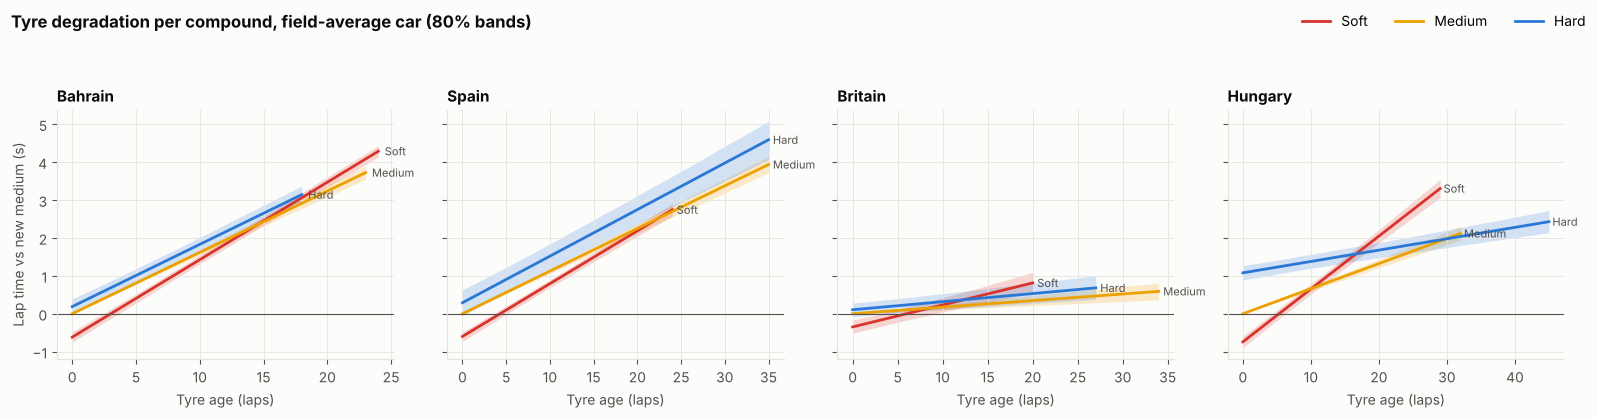

In [6]:
F.plot_deg_curves(fd.deg_curves_table(), show=True);

## Extrapolation: XGBoost vs Bayesian vs actual on `long_tyre`

Both models are trained only on tyre age ≤ 15 laps. Left: mean signed error by
tyre age (positive = predicted too slow). Right: one long stint, actual laps vs
both models.

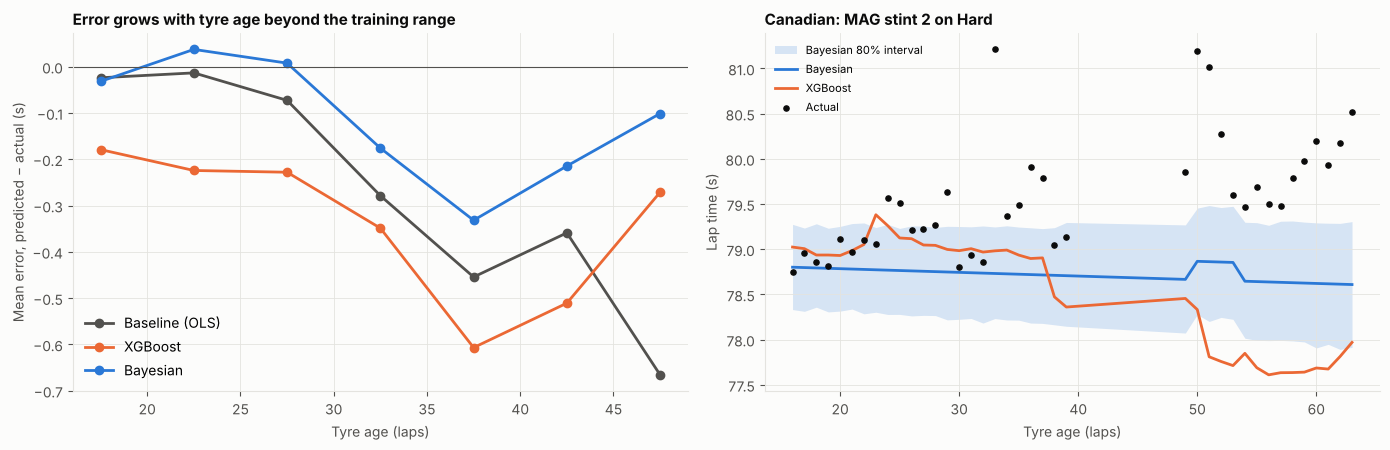

model,Baseline (OLS),Bayesian,XGBoost
age_mid,,,
17.5,-0.024,-0.032,-0.179
22.5,-0.013,0.037,-0.224
27.5,-0.073,0.008,-0.228
32.5,-0.279,-0.176,-0.349
37.5,-0.454,-0.332,-0.607
42.5,-0.359,-0.215,-0.511
47.5,-0.666,-0.101,-0.271


In [7]:
long_tyre = fd.long_tyre_tables()
errors = long_tyre["xgb_vs_bayes_long_tyre_errors"]
F.plot_long_tyre(errors, long_tyre["xgb_vs_bayes_long_tyre_stint"], show=True)
errors.pivot(index="age_mid", columns="model", values="mean_error_s").round(3)

### Error by tyre age on `long_tyre`

Aggregate MAE is close for all three models, so the extrapolation claim rests on
how error grows with tyre age. Mean error is predicted − actual (positive =
predicted too slow).

In [8]:
by_age = error_by_tyre_age(laps, split_fits["long_tyre"])
if WRITE_TABLES:
    by_age.to_csv(FIG_DIR / "long_tyre_by_age.csv", index=False)
wide = by_age.pivot(index="bucket", columns="model", values=["mae_s", "mean_error_s"])
wide = wide.reindex(["16-20", "21-30", "31-40", "40+"])
n = by_age.groupby("bucket")["n"].first().reindex(wide.index)
md_table = pd.DataFrame({
    "Tyre age": wide.index, "Laps": n.to_numpy(),
    **{f"MAE {m}": wide[("mae_s", m)].round(3).to_numpy() for m in ["baseline", "xgboost", "bayes"]},
    **{f"Mean error {m}": wide[("mean_error_s", m)].round(3).to_numpy() for m in ["baseline", "xgboost", "bayes"]},
})
if WRITE_TABLES:
    (FIG_DIR / "long_tyre_by_age.md").write_text(md_table.to_markdown(index=False) + "\n")
md_table

,Tyre age,Laps,MAE baseline,MAE xgboost,MAE bayes,Mean error baseline,Mean error xgboost,Mean error bayes
0,16-20,2433,0.468,0.429,0.443,-0.024,-0.179,-0.032
1,21-30,2291,0.523,0.507,0.524,-0.036,-0.226,0.026
2,31-40,708,0.662,0.712,0.615,-0.332,-0.427,-0.223
3,40+,107,0.882,1.067,0.773,-0.652,-0.555,-0.246


## Leclerc, Hungary 2022: hard stint, laps 41–53

Full-data fit, so these laps are in the training data: this checks fit, not
forecasting. Dots are actual laps; the line and band are the model's mean and
80% prediction interval.

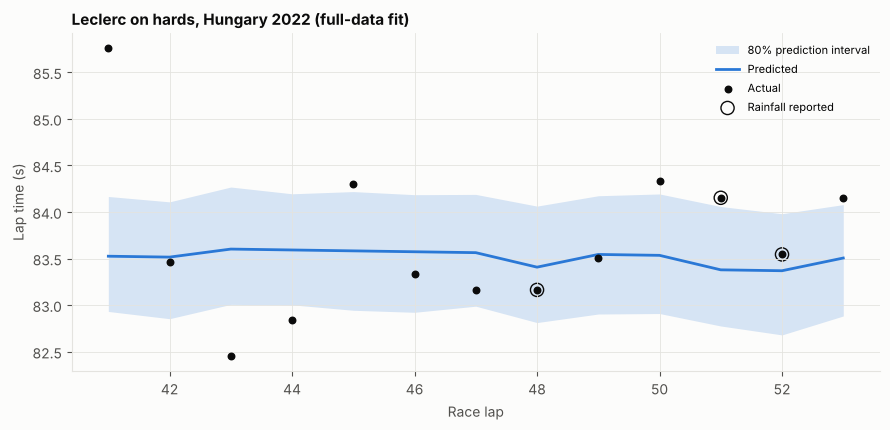

,race_lap,TyreLife,actual,predicted,lo,hi,rainfall
0,41,2,85.755,83.525,82.932,84.166,False
1,42,3,83.462,83.515,82.854,84.108,False
2,43,4,82.456,83.601,83.007,84.267,False
3,44,5,82.839,83.592,83.003,84.195,False
4,45,6,84.300,83.582,82.944,84.219,False
5,46,7,83.335,83.573,82.923,84.185,False
6,47,8,83.158,83.563,82.988,84.188,False
7,48,9,83.163,83.407,82.812,84.063,True
8,49,10,83.509,83.544,82.904,84.174,False
9,50,11,84.334,83.534,82.909,84.193,False


In [9]:
lec = fd.leclerc_hungary_hard_table()
F.plot_leclerc_hungary_hard(lec, show=True)
lec.round(3)

## Ferrari's compound terms at Hungary (full data)

Reported only; interpreted in Phase 6. `team_compound` is Ferrari's deviation
from the field at this race (medium = 0), `field_compound` the field's offset,
`total` their sum, and `team_deg_s_per_lap` Ferrari's season deg vs the field.

In [10]:
team_compound_summary(full, "Ferrari", 13).round(3)

,team,RoundNumber,compound,term,mean,lo,hi
0,Ferrari,13,SOFT,team_compound,-0.004,-0.143,0.139
1,Ferrari,13,SOFT,field_compound,-0.742,-0.898,-0.591
2,Ferrari,13,SOFT,total,-0.745,-0.963,-0.544
3,Ferrari,13,SOFT,team_deg_s_per_lap,0.008,0.004,0.012
4,Ferrari,13,MEDIUM,team_compound,0.000,0.000,0.000
5,Ferrari,13,MEDIUM,field_compound,0.000,0.000,0.000
6,Ferrari,13,MEDIUM,total,0.000,0.000,0.000
7,Ferrari,13,MEDIUM,team_deg_s_per_lap,0.007,0.004,0.009
8,Ferrari,13,HARD,team_compound,0.133,0.000,0.265
9,Ferrari,13,HARD,field_compound,1.079,0.894,1.271


### Confounding check: Leclerc's stint vs Ferrari's hard term

Leclerc's stint 3 is Ferrari's only hard stint at Hungary, so his stint effect
and `team_compound[Ferrari, hard, Hungary]` are fitted from the same laps.

In [11]:
pd.Series(stint_team_confounding(full, 13, "LEC", 3, "Ferrari", "HARD")).round(3)

correlation          -0.382
team_compound_mean    0.133
team_compound_lo      0.000
team_compound_hi      0.265
stint_effect_mean     0.087
stint_effect_lo      -0.089
stint_effect_hi       0.264
sum_mean              0.220
sum_lo                0.042
sum_hi                0.398
dtype: float64

## Flags: hard degrading faster than soft, or negative degradation

Field-average linear deg per race and compound (s/lap). Flagged, not forced.

In [12]:
flags = deg_by_race(full).assign(Event=lambda d: d["RoundNumber"].map(event))
flagged = flags[flags["negative"] | flags["hard_faster_than_soft"]]
flagged.round(3)

,RoundNumber,compound,mean,lo,hi,p_negative,p_hard_gt_soft,negative,hard_faster_than_soft,Event
5,2,HARD,-0.001,-0.010,0.008,0.554,0.066,True,False,Saudi Arabian
8,3,HARD,-0.004,-0.012,0.005,0.714,0.061,True,False,Australian
9,5,SOFT,-0.001,-0.029,0.029,0.506,0.543,True,True,Miami
10,5,MEDIUM,0.003,-0.006,0.010,0.346,0.543,False,True,Miami
11,5,HARD,0.003,-0.004,0.010,0.285,0.543,False,True,Miami
48,21,SOFT,0.056,0.050,0.062,0.000,0.977,False,True,São Paulo
49,21,MEDIUM,0.069,0.063,0.075,0.000,0.977,False,True,São Paulo
50,21,HARD,0.109,0.076,0.143,0.000,0.977,False,True,São Paulo
